# Learning Dependencies with Bayesian Networks

This activity explores the trade-off between model complexity and generalization by comparing a Naive Bayes classifier with a Bayesian Network. Using the UCI Heart Disease dataset, I implemented a Structure Learning algorithm (Hill Climbing with K2 Score) using the bnlearn library. The goal is to verify if modeling the conditional dependencies between medical features (e.g., Age, Cholesterol, Heart Rate) improves prediction accuracy compared to the independence assumption of the Naive Bayes approach.

In [ ]:
#  1. SETUP AND INSTALLATION
!pip install bnlearn > /dev/null

import bnlearn as bn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import CategoricalNB

In [ ]:
#  2. DATA LOADING (UCI Heart Disease)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
columns = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
           'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

# Loading and cleaning
df = pd.read_csv(url, names=columns, na_values="?")
df = df.dropna()

# Target Binarization: 0 = No Disease, 1 = Disease (originally 1-4)
df['target'] = df['target'].apply(lambda x: 1 if x > 0 else 0)

# Discretization
# Bayesian Networks and K2 Score work best with discrete data bins
for col in ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']:
    df[col] = pd.qcut(df[col], q=3, labels=False, duplicates='drop')

# Train/Test Split
train_data, test_data = train_test_split(df, test_size=0.2, random_state=42)
print(f"Data Loaded. Training samples: {len(train_data)}, Test samples: {len(test_data)}")

Data Loaded. Training samples: 237, Test samples: 60


**The Naive Bayes Classifier**

 The Naive Bayes classifier is a probabilistic algorithm based on Bayes' theorem. Its defining characteristic is the conditional independence assumption: it assumes that the value of a specific feature is independent of the value of any other feature, given the class variable.Mathematically, for a class $Y$ and features $X = \{x_1, x_2, ..., x_n\}$:$$P(X|Y) = \prod_{i=1}^{n} P(x_i | Y)$$While this assumption is often violated in real-world data (especially in medical diagnostics where symptoms are correlated), the model is computationally efficient and surprisingly robust in terms of classification accuracy.

In [ ]:
#  3. BASELINE: NAIVE BAYES
# We first test the standard approach seen in class
nb = CategoricalNB()
X_train = train_data.drop('target', axis=1)
y_train = train_data['target']
X_test = test_data.drop('target', axis=1)
y_test = test_data['target']

nb.fit(X_train, y_train)
nb_pred = nb.predict(X_test)
nb_acc = accuracy_score(y_test, nb_pred)

print("\n--- Naive Bayes Results ---")
print(f"Accuracy: {nb_acc:.4f}")


--- Naive Bayes Results ---
Accuracy: 0.8667


**Bayesian Belief Networks**

Bayesian Networks relax the rigid independence assumption of the Naive Bayes. They allow us to model conditional dependencies explicitly using a Directed Acyclic Graph (DAG).

* Nodes represent variables (features).

* Edges represent conditional dependencies.

* Each node is associated with a conditional probability table (CPT).

In this exercise, we do not fix the structure manually; instead, we use Structure Learning to discover the dependencies directly from the data.

In [ ]:
#  4. BAYESIAN NETWORK (Structure Learning)
print("\n--- Starting Structure Learning with bnlearn ---")
print("Algorithm: Hill Climbing Search | Score: K2")

# bnlearn performs Structure Learning (DAG estimation) + Parameter Learning (CPT)
# We use Hill Climbing (hc) and K2 Score (k2)
model = bn.structure_learning.fit(train_data, methodtype='hc', scoretype='k2', verbose=0)
model = bn.parameter_learning.fit(model, train_data, verbose=0)


--- Starting Structure Learning with bnlearn ---
Algorithm: Hill Climbing Search | Score: K2



Learned Graph (Dependencies found):
[bnlearn] >Set node properties.
[bnlearn] >Set edge properties.
[bnlearn] >Plot based on Bayesian model


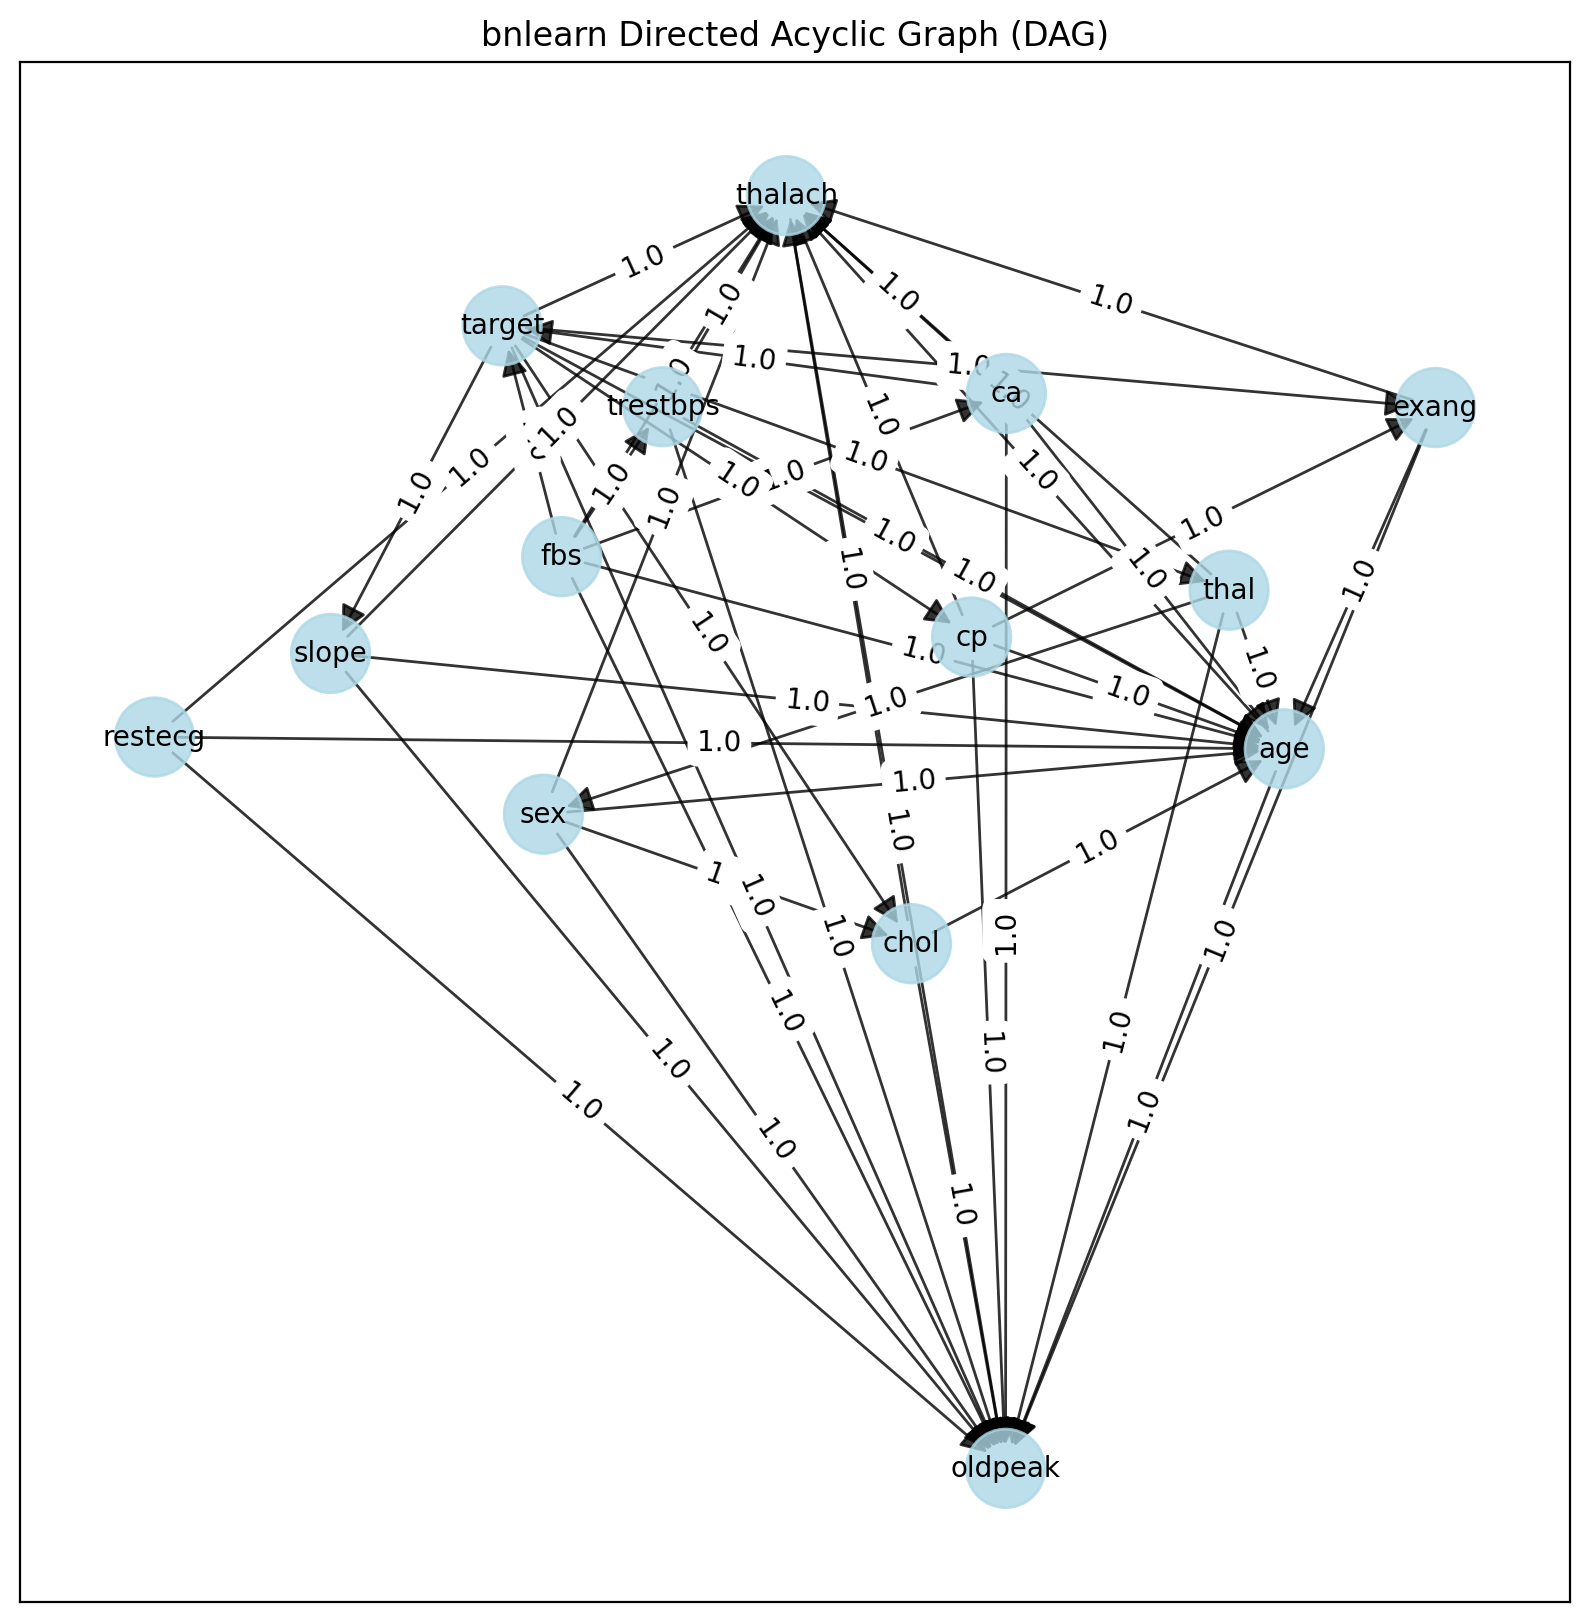

In [ ]:
#  5. VISUALIZATION
# Plotting the learned dependencies
print("\nLearned Graph (Dependencies found):")
bn.plot(model, interactive=False)
plt.show()

In [ ]:
# 6. INFERENZA (PREDICTION)
print("Running inference on test set (computing probabilities)...")
# bnlearn's predict function uses the network to infer the target
bn_preds = bn.predict(model, test_data, variables=['target'])
bn_acc = accuracy_score(test_data['target'], bn_preds['target'])

print(f"\n--- Bayesian Network Results ---")
print(f"Accuracy: {bn_acc:.4f}")

Running inference on test set (computing probabilities)...
[bnlearn]> Remaining columns for inference: 13


100%|██████████| 60/60 [00:01<00:00, 31.16it/s]


--- Bayesian Network Results ---
Accuracy: 0.6833


**Discussion of Results**

In this experiment, I compared the standard Naive Bayes classifier with a learned Bayesian Network (BN). The results obtained are:

* Naive Bayes Accuracy: 0.8667 (86.67%)

* Bayesian Network Accuracy: 0.6833 (68.33%)

Contrary to the initial hypothesis that modeling dependencies would improve performance, the Naive Bayes significantly outperformed the Bayesian Network.

**Bias-Variance Trade-off**: Naive Bayes has high bias (due to the strong independence assumption) but very low variance.On small datasets, the low variance of the "naive" assumption often dominates the error, making it more robust than complex models.

**Interpretability**: Despite the lower accuracy, the Bayesian Network provided a learned graph (visible in the output). This graph offers "White Box" interpretability, showing us which variables the algorithm considers related (e.g., links between Age and Heart Rate), which is a feature the Naive Bayes "Black Box" lacks.

**Conclusion**

This activity demonstrates that while Bayesian Networks are theoretically more expressive than Naive Bayes, they are more prone to overfitting on small datasets. For this specific medical task with limited records, the robust simplicity of Naive Bayes proved superior.

